# Vit using MONAI

## Check GPU

In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA compiled:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: C:\Users\user\anaconda3\envs\monai\python.exe
PyTorch: 2.11.0+cu128
CUDA compiled: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5070


## Random seed

In [2]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# More deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Random seed: {SEED}")

Random seed: 42


## Imports

In [3]:
import logging
import numpy as np
import os
from pathlib import Path
import sys
import tempfile
import torch
import ignite

from monai.config import print_config
from monai.data import DataLoader
from monai.engines import SupervisedTrainer, SupervisedEvaluator
from monai.handlers import (
    StatsHandler,
    TensorBoardStatsHandler,
    ValidationHandler,
    CheckpointSaver,
    CheckpointLoader,
    ClassificationSaver,
)
from monai.handlers.utils import from_engine
from monai.inferers import SimpleInferer
from monai.networks.nets import ViT
from monai.transforms import LoadImageD, EnsureChannelFirstD, ScaleIntensityD, Compose, AsDiscreted
from monai.data import Dataset
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Resized,
    ScaleIntensityd,
    EnsureTyped,
)

print_config()

C:\Users\user\anaconda3\envs\monai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MONAI version: 1.6.0
Numpy version: 2.2.6
Pytorch version: 2.11.0+cu128
MONAI flags: HAS_EXT = False, USE_COMPILED = False, USE_META_DICT = False
MONAI rev id: eccefc57550b111ed781d82249dfe77872a0e918
MONAI __file__: C:\Users\<username>\anaconda3\envs\monai\lib\site-packages\monai\__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.4.2
scikit-image version: NOT INSTALLED or UNKNOWN VERSION.
scipy version: 1.15.3
Pillow version: 12.3.0
Tensorboard version: 2.21.0
gdown version: NOT INSTALLED or UNKNOWN VERSION.
TorchVision version: 0.26.0+cu128
tqdm version: 4.70.1
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 7.2.2
pandas version: 2.3.3
einops version: 0.8.2
transformers version: NOT INSTALLED or UNKNOWN VERSION.
mlflow version: NOT INSTALLED or UNKNOWN VERSION.
pynrrd version: NOT INSTALLED or UNKNOWN VERSION.
clearml version: NOT INSTALLED or UNKNOWN VERSION.


## Loading Dataset

In [4]:
DATA_DIR = Path(
    r"..\data\brain-tumor-mri-classification\merged_dataset_v3\images"
)

In [5]:
class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary",
]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

In [6]:
def get_image_files(split):
    split_dir = DATA_DIR / split
    data = []

    for class_name in class_names:
        class_dir = split_dir / class_name

        for image_path in class_dir.iterdir():
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                data.append(
                    {
                        "image": str(image_path),
                        "label": class_to_idx[class_name],
                    }
                )

    return data

In [7]:
transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(224, 224)),
    ScaleIntensityd(keys=["image"]),
    EnsureTyped(keys=["image"]),
])

In [8]:
train_files = get_image_files("train")
val_files = get_image_files("val")
test_files = get_image_files("test")

In [9]:
train_dataset = Dataset(
    data=train_files,
    transform=transforms,
)

val_dataset = Dataset(
    data=val_files,
    transform=transforms,
)

test_dataset = Dataset(
    data=test_files,
    transform=transforms,
)

In [10]:
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("First sample:", train_dataset[0])

Train images: 8306
Validation images: 488
Test images: 246
First sample: {'image': metatensor([[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0041, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0123, 0.0123, 0.0123],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0082, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0041]],

        [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0041, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0123, 0.0123, 0.0123],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0082, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0041]],

        [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  .

In [11]:
sample = train_dataset[0]

print(type(sample))
print(sample.keys())

<class 'dict'>
dict_keys(['image', 'label'])


In [12]:
print("Image Type :", type(sample["image"]))
print("Image Shape:", sample["image"].shape)
print("Image dtype:", sample["image"].dtype)
print("Label:", sample["label"])

Image Type : <class 'monai.data.meta_tensor.MetaTensor'>
Image Shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Label: 0


## Select subset of dataset

In [13]:
from torch.utils.data import Subset
import random

random.seed(42)

subset_size = 8306

train_indices = random.sample(
    range(len(train_dataset)),
    min(subset_size, len(train_dataset))
)

val_indices = random.sample(
    range(len(val_dataset)),
    min(subset_size, len(val_dataset))
)

test_indices = random.sample(
    range(len(test_dataset)),
    min(subset_size, len(test_dataset))
)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)
test_subset = Subset(test_dataset, test_indices)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_subset))

Training images: 8306
Validation images: 488
Test images: 246


## Training Model

In [14]:
max_epochs = 50
save_interval = 2
out_dir = "../eval/vit"

device = torch.device("cuda:0")

class ViTWrapper(torch.nn.Module):
    def __init__(self, vit_model):
        super().__init__()
        self.vit_model = vit_model

    def forward(self, x):
        outputs = self.vit_model(x)
        # Return only the first element (logits) if it's a tuple
        if isinstance(outputs, tuple):
            return outputs[0]
        return outputs

base_model = ViT(in_channels=3, img_size=(224, 224), patch_size=(16, 16), num_classes=4, spatial_dims=2, classification=True)
model = ViTWrapper(base_model).to(device)

loss_fn = torch.nn.CrossEntropyLoss()

logging.basicConfig(
    stream=sys.stdout,
    level=logging.INFO,
)

# --------------------------------------------------
# VALIDATION METRICS
# --------------------------------------------------

evaluator = SupervisedEvaluator(
    device=device,
    val_data_loader=DataLoader(
        val_dataset,
        batch_size=512,
        shuffle=False,
        num_workers=0,
    ),
    network=model,
    inferer=SimpleInferer(),
    key_val_metric={
        "val_accuracy": ignite.metrics.Accuracy(
            output_transform=from_engine(["pred", "label"])
        ),

        "val_loss": ignite.metrics.Loss(
            loss_fn=loss_fn,
            output_transform=from_engine(["pred", "label"]),
        ),
    },

    val_handlers=[
        StatsHandler(
            iteration_log=False,
        ),

        TensorBoardStatsHandler(
            iteration_log=False,
            tag_name="validation",
        ),
    ],
)

# --------------------------------------------------
# TRAINING
# --------------------------------------------------

trainer = SupervisedTrainer(
    device=device,
    max_epochs=max_epochs,

    train_data_loader=DataLoader(
        train_subset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
    ),

    network=model,

    optimizer=torch.optim.Adam(
        model.parameters(),
        lr=1e-5,
    ),

    loss_function=loss_fn,
    inferer=SimpleInferer(),

    key_train_metric={
        "train_accuracy": ignite.metrics.Accuracy(
            output_transform=from_engine(["pred", "label"])
        ),
        "train_loss": ignite.metrics.Loss(
            loss_fn=loss_fn,
            output_transform=from_engine(["pred", "label"]),
        ),
    },

    train_handlers=[
        ValidationHandler(
            validator=evaluator,
            epoch_level=True,
            interval=1,
        ),

        CheckpointSaver(
            save_dir=out_dir,
            save_dict={"model": model},
            save_interval=save_interval,
            save_final=True,
            final_filename="monai_vit.pt",
        ),

        # StatsHandler(),

        TensorBoardStatsHandler(
            tag_name="train",
            output_transform=from_engine(
                ["loss"],
                first=True,
            ),
        ),
    ],
)

In [15]:
from ignite.engine import Events
import datetime

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

@trainer.on(Events.EPOCH_COMPLETED)
def log_epoch_metrics(engine):
    epoch = engine.state.epoch

    train_accuracy = engine.state.metrics.get("train_accuracy")
    train_loss = engine.state.metrics.get("train_loss")

    val_accuracy = evaluator.state.metrics.get("val_accuracy")
    val_loss = evaluator.state.metrics.get("val_loss")

    current_time = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    epoch_duration = engine.state.times.get(Events.EPOCH_COMPLETED.name, 0.0)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"\n {current_time} | "
        f"Epoch {epoch}/{max_epochs} | "
        f"Train Accuracy: {train_accuracy} | "
        f"Train Loss: {train_loss} | "
        f"Val Accuracy: {val_accuracy} | "
        f"Val Loss: {val_loss} | "
        f"Time taken: {epoch_duration}\n"
    )

In [16]:
trainer.run()

INFO:ignite.engine.engine.SupervisedTrainer:Engine run resuming from iteration 0, epoch 0 until 50 epochs
INFO:ignite.engine.engine.SupervisedTrainer:Got new best metric of train_accuracy: 0.5358776787864195
INFO:ignite.engine.engine.SupervisedEvaluator:Engine run resuming from iteration 0, epoch 0 until 1 epochs
INFO:ignite.engine.engine.SupervisedEvaluator:Got new best metric of val_accuracy: 0.5778688524590164
2026-09-25 12:48:55,932 - INFO - Epoch[1] Metrics -- val_accuracy: 0.5779 val_loss: 0.9774 
2026-09-25 12:48:55,932 - INFO - Key metric: val_accuracy best value: 0.5778688524590164 at epoch: 1
INFO:ignite.engine.engine.SupervisedEvaluator:Epoch[1] Complete. Time taken: 00:00:36.833
INFO:ignite.engine.engine.SupervisedEvaluator:Engine run finished. Time taken: 00:00:36.834

 2026-09-25 12:48:55 | Epoch 1/50 | Train Accuracy: 0.5358776787864195 | Train Loss: 1.0816310310317843 | Val Accuracy: 0.5778688524590164 | Val Loss: 0.9774255596223425 | Time taken: 86.84524512290955

INFO

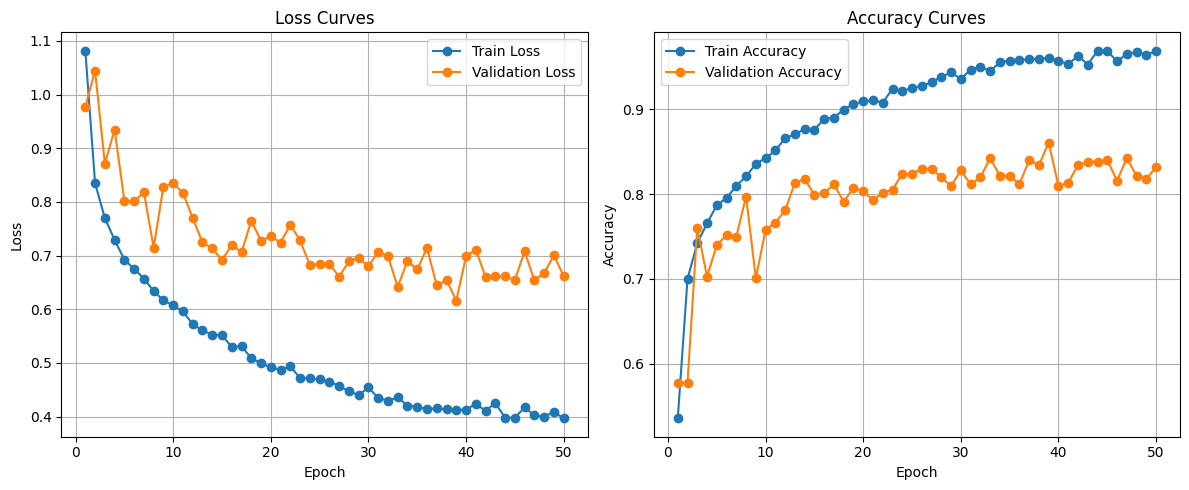

In [19]:
import matplotlib.pyplot as plt

epochs = range(1, max_epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Train Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Train Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
import torch
from monai.data import DataLoader

test_loader = DataLoader(
    test_subset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        logits = model(images)

        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = correct / total

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 80.08%


## Evaluation

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

In [21]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

In [22]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

ViTWrapper(
  (vit_model): ViT(
    (patch_embedding): PatchEmbeddingBlock(
      (patch_embeddings): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (blocks): ModuleList(
      (0-11): 12 x TransformerBlock(
        (mlp): MLPBlock(
          (linear1): Linear(in_features=768, out_features=3072, bias=True)
          (linear2): Linear(in_features=3072, out_features=768, bias=True)
          (fn): GELU(approximate='none')
          (drop1): Dropout(p=0.0, inplace=False)
          (drop2): Dropout(p=0.0, inplace=False)
        )
        (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): SABlock(
          (out_proj): Linear(in_features=768, out_features=768, bias=True)
          (qkv): Linear(in_features=768, out_features=2304, bias=False)
          (to_q): Identity()
          (to_k): Identity()
          (to_v): Identity()
          (input_rearrange): Rearrange('b h (qkv l d) -> qkv b l h d', qkv

In [23]:
all_labels = []
all_predictions = []

with torch.inference_mode():
    for batch in test_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        # Model output: [batch_size, 4]
        logits = model(images)

        # Convert logits into predicted class indices
        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

### Accuracy, Precision, Recall, F1 Score

In [24]:
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0,
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0,
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0,
)

print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall   : {recall:.4f}")
print(f"Test F1 Score : {f1:.4f}")

Test Accuracy : 0.8008
Test Precision: 0.8440
Test Recall   : 0.8008
Test F1 Score : 0.7571


### Classificaiton Report

In [25]:
print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
)


Classification Report:

              precision    recall  f1-score   support

      glioma       0.84      1.00      0.91        81
  meningioma       0.70      0.98      0.82        55
    no_tumor       0.82      0.96      0.89        49
   pituitary       1.00      0.25      0.39        61

    accuracy                           0.80       246
   macro avg       0.84      0.80      0.75       246
weighted avg       0.84      0.80      0.76       246



### Confusion Matrix

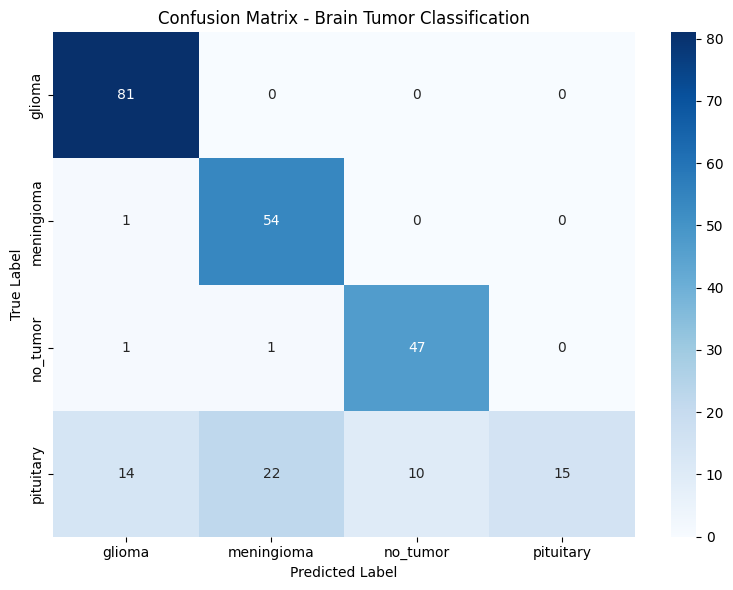

In [26]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Brain Tumor Classification")
plt.tight_layout()
plt.show()